<a href="https://colab.research.google.com/github/Mthairr/Car-Insurance-pricing-project/blob/main/Tarification_automobile_par_Machine_Learning3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarification automobile par Machine Learning

# Contexte métier
En assurance automobile, la prime est le prix payé par l’assuré pour être couvert en cas de sinistre. Pour fixer ce prix, l’assureur doit concilier deux objectifs :

— **être compétitif** : proposer à chaque client un tarif au plus juste de son risque, sans quoi les bons conducteurs partiront chez un concurrent moins cher ;

— **être rentable** : sur l’ensemble du portefeuille, les primes encaissées doivent couvrir en moyenne le coût des indemnisations.

La **prime pure** correspond au coût moyen attendu des sinistres d’un client sur la période de couverture. En notant $S$ le montant total des sinistres d’un client sur cette période, elle se décompose ainsi :

$$\underbrace{E[S]}_{\text{prime pure}} = \underbrace{P(S > 0)}_{\text{probabilité de sinistre}} \times \underbrace{E[S \mid S > 0]}_{\text{montant attendu si sinistre}}$$


Cette décomposition conduit naturellement à construire deux modèles distincts :

— **un modèle de fréquence (classification)** : prédire la probabilité qu’un client ait au moins un sinistre ;

— **un modèle de gravité (régression)** : prédire le montant des sinistres, sachant qu’au moins un sinistre a eu lieu.

La prime prédite pour un client est alors le produit des sorties de ces deux modèles.

# Analyse Exploratoire des données

Les 2 variables cibles sont :
- nombre_sinistres
- montant_sinistre

### Chargement des données et importatiuon des bibliothèques python qui seront utilisés pour ce projet

In [1]:
!git clone https://github.com/Mthairr/Car-Insurance-pricing-project.git

Cloning into 'Car-Insurance-pricing-project'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 25 (delta 5), reused 11 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 7.39 MiB | 7.07 MiB/s, done.
Resolving deltas: 100% (5/5), done.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Définition des chemins d'accès aux fichiers
data_dir = '/content/Car-Insurance-pricing-project'
train_path = os.path.join(data_dir, 'train.csv')
test_path = os.path.join(data_dir, 'test.csv')

# Chargement des données
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

# Affichage des dimensions des datasets
print(f"Jeu d'entraînement (Train) : {train_df.shape[0]} lignes, {train_df.shape[1]} variables")
print(f"Jeu de test (Test) : {test_df.shape[0]} lignes, {test_df.shape[1]} variables")

# On visualise les premières lignes du dataset d'entraînement
display(train_df.head())

Jeu d'entraînement (Train) : 50000 lignes, 33 variables
Jeu de test (Test) : 50000 lignes, 28 variables


,index,id_client,id_vehicule,id_contrat,bonus,type_contrat,duree_contrat,anciennete_info,freq_paiement,paiement,...,marque_vehicule,modele_vehicule,debut_vente_vehicule,fin_vente_vehicule,vitesse_vehicule,type_vehicule,prix_vehicule,poids_vehicule,nombre_sinistres,montant_sinistre
0,0,A00000001,V01,A00000001-V01,0.5,Maxi,29,9,Biannual,No,...,PEUGEOT,306,10,9,182,Tourism,20700,1210,0,0.0
1,1,A00000002,V01,A00000002-V01,0.5,Maxi,3,1,Biannual,No,...,MERCEDES BENZ,C220,4,2,229,Tourism,34250,1510,0,0.0
2,2,A00000003,V01,A00000003-V01,0.5,Maxi,2,2,Yearly,No,...,BMW,Z3,12,11,210,Tourism,28661,1270,0,0.0
3,3,A00000004,V01,A00000004-V01,0.5,Median2,22,1,Yearly,No,...,VOLKSWAGEN,GOLF,18,15,180,Tourism,14407,1020,0,0.0
4,4,A00000005,V01,A00000005-V01,0.5,Maxi,16,4,Biannual,No,...,RENAULT,LAGUNA,13,11,195,Tourism,16770,1230,0,0.0


On observe que le dataset train comporte 33 champs alors que le dataset test contient seulement 28 champs.

Ces 5 champs ne sont pas présent dans le dataset de test :
- id_client
- id_vehicule
- id_contrat
- nombre_sinistres (var cible 1)
- nombre_sinistre (var cible 2)

Il est normal de ne pas voir les variables cibles dans le dataset test. Cependant pour les 3 autres champ, cela peut s'expliquer par le fait que ce sont des valeurs uniques (sauf pour id_vehicule).


### Analyse globale du jeu de données d'entraînement

=== Distribution de 'nombre_sinistres' ===
nombre_sinistres
0    47083
1     2917
Name: count, dtype: int64

=== Description de 'montant_sinistre' ===
count    50000.000000
mean       103.369344
std        545.402879
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      21826.960000
Name: montant_sinistre, dtype: float64

Pourcentage de contrats sans sinistre (montant = 0€) : 94.17%

Moyenne globale des montants (sur tout le dataset) : 103.37€

Moyenne des montants pour les dossiers sinistrés (> 0€) : 1771.84€

Montant maximum enregistré : 21826.96€


/tmp/ipykernel_1663/4112034511.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='nombre_sinistres', ax=axes[0], palette='viridis')


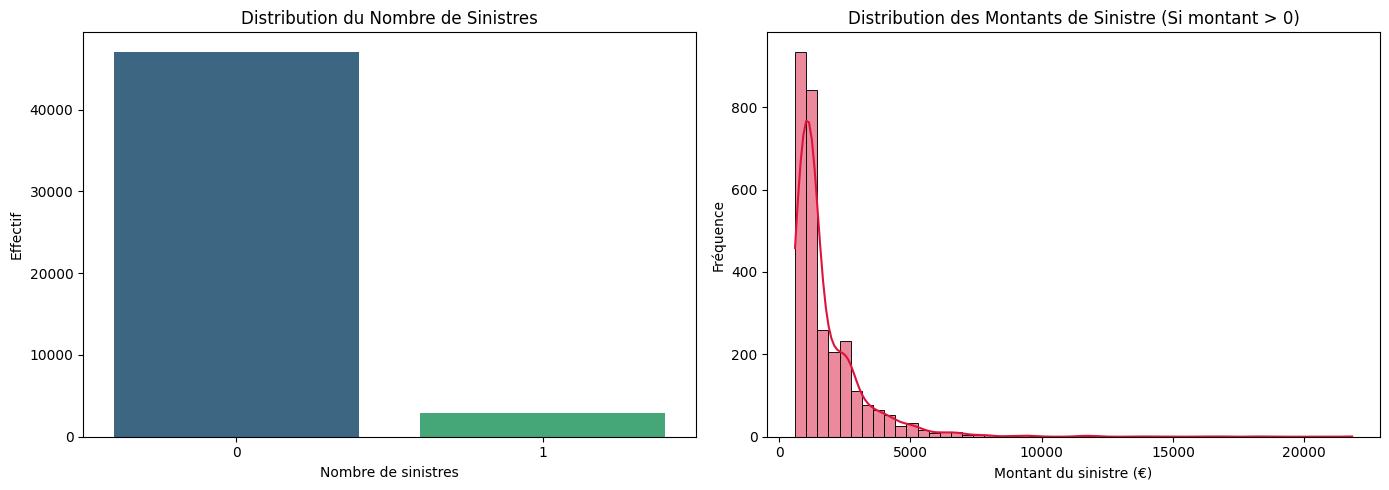

In [3]:
# Analyse de la répartition des variables cibles dans le jeu d'entraînement
print("=== Distribution de 'nombre_sinistres' ===")
print(train_df['nombre_sinistres'].value_counts(dropna=False))

print("\n=== Description de 'montant_sinistre' ===")
print(train_df['montant_sinistre'].describe())

# Calcul du pourcentage de lignes avec un montant de 0€
pct_zero = (train_df['montant_sinistre'] == 0).mean() * 100

# Calcul de la moyenne globale de tous les montants
moyenne_globale = train_df['montant_sinistre'].mean()

# Filtrage des dossiers avec sinistre (montant > 0)
sinistres_strictement_positifs = train_df[train_df['montant_sinistre'] > 0]

# Calcul de la moyenne et du maximum pour les dossiers avec sinistre
moyenne_sinistres_positifs = sinistres_strictement_positifs['montant_sinistre'].mean()
max_sinistre = sinistres_strictement_positifs['montant_sinistre'].max()

# Affichage des résultats
print(f"\nPourcentage de contrats sans sinistre (montant = 0€) : {pct_zero:.2f}%")
print(f"\nMoyenne globale des montants (sur tout le dataset) : {moyenne_globale:.2f}€")
print(f"\nMoyenne des montants pour les dossiers sinistrés (> 0€) : {moyenne_sinistres_positifs:.2f}€")
print(f"\nMontant maximum enregistré : {max_sinistre:.2f}€")

# Visualisation des distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Nombre de sinistres
sns.countplot(data=train_df, x='nombre_sinistres', ax=axes[0], palette='viridis')
axes[0].set_title("Distribution du Nombre de Sinistres")
axes[0].set_xlabel("Nombre de sinistres")
axes[0].set_ylabel("Effectif")

# Graphique 2 : Montant de sinistre (uniquement pour les dossiers avec sinistre > 0)
sinistres_positifs = train_df[train_df['montant_sinistre'] > 0]
sns.histplot(data=sinistres_positifs, x='montant_sinistre', bins=50, kde=True, ax=axes[1], color='crimson')
axes[1].set_title("Distribution des Montants de Sinistre (Si montant > 0)")
axes[1].set_xlabel("Montant du sinistre (€)")
axes[1].set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

Taille du train dataset : 50 000 lignes
Chaque ligne représente un contrat client.

nombre_sinistres :
- 0 sinistre : 47 083 observations/contrat clients qui ont aucun sinistre.
- 1 sinistre : 2 917 (soit 5.8%) observations/contrat clients qui ont 1 sinistre.

=> La cible nombre_sinistres est une cible binaire fortement déséquilibrée de type entier.


montant_sinistre :
- 94.2% des lignes ont un montant de 0€ (ce qui correspond aux clients sans sinsitres).
- En moyenne, sur tout le dataset, le montant des sinistres est de 103€.
- Sur l'ensemble des dossiers sinistrés, la moyenne des montants est de 1 771€.
- Le contratc avec le plus grand montant de sinistre enregistré est de 21 826€.
- On observe une distribution très asymétrique avec une longue queue vers la droite qui correspond à la valeur max de 21 826€.

=> Cette variable cible est une variable quantitative de type float.

### Analyse descriptive des variables explicatives

Dans les étapes précèdentes, on a pu observer la non présence de 5 champs dans le dataset test qui sont bien présents dans le dataset train. Nous allons donc les exclures (plus l'index car c'est un identifiant unique) car ils ne feront pas partis des variables explicatives pour entrainer puis évaluer le modèle.

In [4]:
# Vérification que la colonne 'index' est un identifiant unique
total_rows = len(train_df)
unique_indices = train_df['index'].nunique()
is_unique = unique_indices == total_rows

print("=== VERIFICATION DE L'UNICITE DE LA COLONNE INDEX ===")
print(f"Nombre total de lignes : {total_rows}")
print(f"Nombre de valeurs uniques dans 'index' : {unique_indices}")
print(f"Est-ce un identifiant unique ? : {'Oui' if is_unique else 'Non'}\n")

=== VERIFICATION DE L'UNICITE DE LA COLONNE INDEX ===
Nombre total de lignes : 50000
Nombre de valeurs uniques dans 'index' : 50000
Est-ce un identifiant unique ? : Oui



In [5]:
# On exclut l'index, les identifiants et les variables cibles de notre analyse descriptive
columns_to_exclude = ['index', 'id_client', 'id_vehicule', 'id_contrat', 'nombre_sinistres', 'montant_sinistre']
explanatory_cols = [col for col in train_df.columns if col not in columns_to_exclude]

# Création d'un sous-DataFrame pour analyser les variables explicatives seulement
expl_df = train_df[explanatory_cols]

# 1. Types de variables et valeurs manquantes
missing_analysis = pd.DataFrame({
    'Type': expl_df.dtypes,
    'Valeurs Manquantes': expl_df.isnull().sum(),
    'Pourcentage Manquant (%)': (expl_df.isnull().sum() / len(expl_df) * 100).round(2),
    'Valeurs Uniques': expl_df.nunique()
})

print("=== ANALYSE GLOBALE DES VARIABLES EXPLICATIVES ===")
display(missing_analysis)

=== ANALYSE GLOBALE DES VARIABLES EXPLICATIVES ===


,Type,Valeurs Manquantes,Pourcentage Manquant (%),Valeurs Uniques
bonus,float64,0,0.00,73
type_contrat,object,0,0.00,4
duree_contrat,int64,0,0.00,41
anciennete_info,int64,0,0.00,25
freq_paiement,object,0,0.00,4
paiement,object,0,0.00,2
utilisation,object,0,0.00,4
code_postal,object,0,0.00,12790
conducteur2,object,0,0.00,2
age_conducteur1,int64,0,0.00,83


Ensuite on analyse en détail les variables catégorielles

In [6]:
# 2. Analyse des variables catégorielles et des modalités rares
print("=== DETAIL DES VARIABLES CATEGORIELLES ET MODALITES RARE ===")
cat_cols = expl_df.select_dtypes(include=['object', 'category']).columns

for col in cat_cols:
    counts = expl_df[col].value_counts(dropna=False)
    pcts = expl_df[col].value_counts(dropna=False, normalize=True) * 100
    summary = pd.DataFrame({'Nombre': counts, 'Pourcentage (%)': pcts.round(2)})
    print(f"\nDistribution pour la variable : {col}")
    display(summary.head(10)) # Afficher les 10 premières modalités pour éviter de surcharger

=== DETAIL DES VARIABLES CATEGORIELLES ET MODALITES RARE ===

Distribution pour la variable : type_contrat


,Nombre,Pourcentage (%)
type_contrat,,
Maxi,32360,64.72
Median2,8759,17.52
Median1,4638,9.28
Mini,4243,8.49



Distribution pour la variable : freq_paiement


,Nombre,Pourcentage (%)
freq_paiement,,
Yearly,18948,37.90
Monthly,15045,30.09
Biannual,14769,29.54
Quarterly,1238,2.48



Distribution pour la variable : paiement


...

,Nombre,Pourcentage (%)
marque_vehicule,,
RENAULT,13317,26.63
PEUGEOT,9747,19.49
CITROEN,7939,15.88
VOLKSWAGEN,2670,5.34
FORD,2184,4.37
OPEL,1835,3.67
TOYOTA,1606,3.21
MERCEDES BENZ,1529,3.06
FIAT,1435,2.87



Distribution pour la variable : modele_vehicule


,Nombre,Pourcentage (%)
modele_vehicule,,
CLIO,3607,7.21
206,1988,3.98
TWINGO,1860,3.72
SCENIC,1663,3.33
MEGANE,1385,2.77
307,1258,2.52
C3,1233,2.47
XSARA,1196,2.39
207,1015,2.03



Distribution pour la variable : type_vehicule


,Nombre,Pourcentage (%)
type_vehicule,,
Tourism,45036,90.07
Commercial,4964,9.93


On observe différents types de données :

- Variables numériques/continues : Liées au client (age, anciennete_permis), liées au contrat (bonus, duree_contrat), et au véhicule (prix_vehicule, vitesse_vehicule, poids_vehicule...).

- Variables catégorielles : Le type de contrat (type_contrat), fréquence de paiment (freq_paiment), l'utilisation du véhicule (utilisation), le sexe du conducteur (sex_conducteur), modèle du véhicule etc.


Concernant les valeurs manquantes (NaN), seulement deux variables explicatives en possède. Il s'agit de sex_conducteur2 avec 66.8% (33 400 lignes) de valeurs manquantes.
sex_conducteur2 correspond au sexe du 2eme conducteur sur le véhicule enregistré sur le contrat du client.
On remarque que les NaN représente le cas où il n'y a pas de 2eme conducteur (cas où conducteur2 = No). On observe également dans le cas où il n'y a pas de conducteur2, age_conducteur2 = 0.

Pour simplifier la compréhension de conducteur2 par le modèle de régression plus tard, nous modifions le type de la variable entier.

Sachant que l'usage du sexe du conducteur est interdit par les réglementations E.U, nous décidons d'enlever cette variable et cela résout le problème de NaN.

In [7]:
#On change le type string en integer
#for df in [train_df, test_df]:
#    df["conducteur2"] = df["conducteur2"].map({"Yes": 1, "No": 0, 1: 1, 0: 0}).astype(int)


#On vérifie si le changement de type à bien fonctionné
display(train_df["conducteur2"].value_counts())

,count
conducteur2,
No,33406
Yes,16594


**La deuxième variable explicative avec des NaN est anciennete_vehicule et qui comporte seulement 1 NaN.      A finir**

In [8]:
mediane = train_df["anciennete_vehicule"].median()
train_df["anciennete_vehicule"] = train_df["anciennete_vehicule"].fillna(mediane)
test_df["anciennete_vehicule"] = test_df["anciennete_vehicule"].fillna(mediane)

Ensuite on analyse en détail les variables numériques afin de détecter des valeurs extrêmes ou non cohérentes et de les corriger. Cela permettra aux modèles d'être entrainé avec des données de meilleures qualités.

=== STATISTIQUES DES VARIABLES NUMERIQUES ===


,bonus,duree_contrat,anciennete_info,age_conducteur1,age_conducteur2,anciennete_permis1,anciennete_permis2,anciennete_vehicule,cylindre_vehicule,din_vehicule,debut_vente_vehicule,fin_vente_vehicule,vitesse_vehicule,prix_vehicule,poids_vehicule
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,49999.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.537911,11.091000,2.726860,54.649940,15.574340,32.444980,9.139800,9.531091,1647.795820,91.547520,11.628320,8.653180,170.731340,18095.562080,1129.088460
std,0.098999,8.567757,2.348558,14.865448,23.993135,13.470428,17.059491,7.012152,463.648632,34.489936,7.756093,6.619901,23.441499,8715.103929,361.006381
min,0.500000,1.000000,1.000000,19.000000,0.000000,1.000000,0.000000,1.000000,0.000000,15.000000,1.000000,1.000000,25.000000,648.000000,0.000000
25%,0.500000,4.000000,1.000000,43.000000,0.000000,22.000000,0.000000,4.000000,1360.000000,68.000000,6.000000,4.000000,157.000000,11950.000000,950.000000
50%,0.500000,9.000000,2.000000,54.000000,0.000000,32.000000,0.000000,8.000000,1587.000000,87.000000,10.000000,7.000000,170.000000,16250.000000,1130.000000
75%,0.500000,16.000000,3.000000,65.000000,34.000000,42.000000,15.000000,13.000000,1910.000000,109.000000,15.000000,12.000000,185.000000,22150.000000,1320.000000
max,2.160000,41.000000,25.000000,101.000000,99.000000,111.000000,111.000000,65.000000,6997.000000,500.000000,74.000000,55.000000,310.000000,155498.000000,3500.000000



=== VISUALISATION DES VARIABLES NUMERIQUES ===


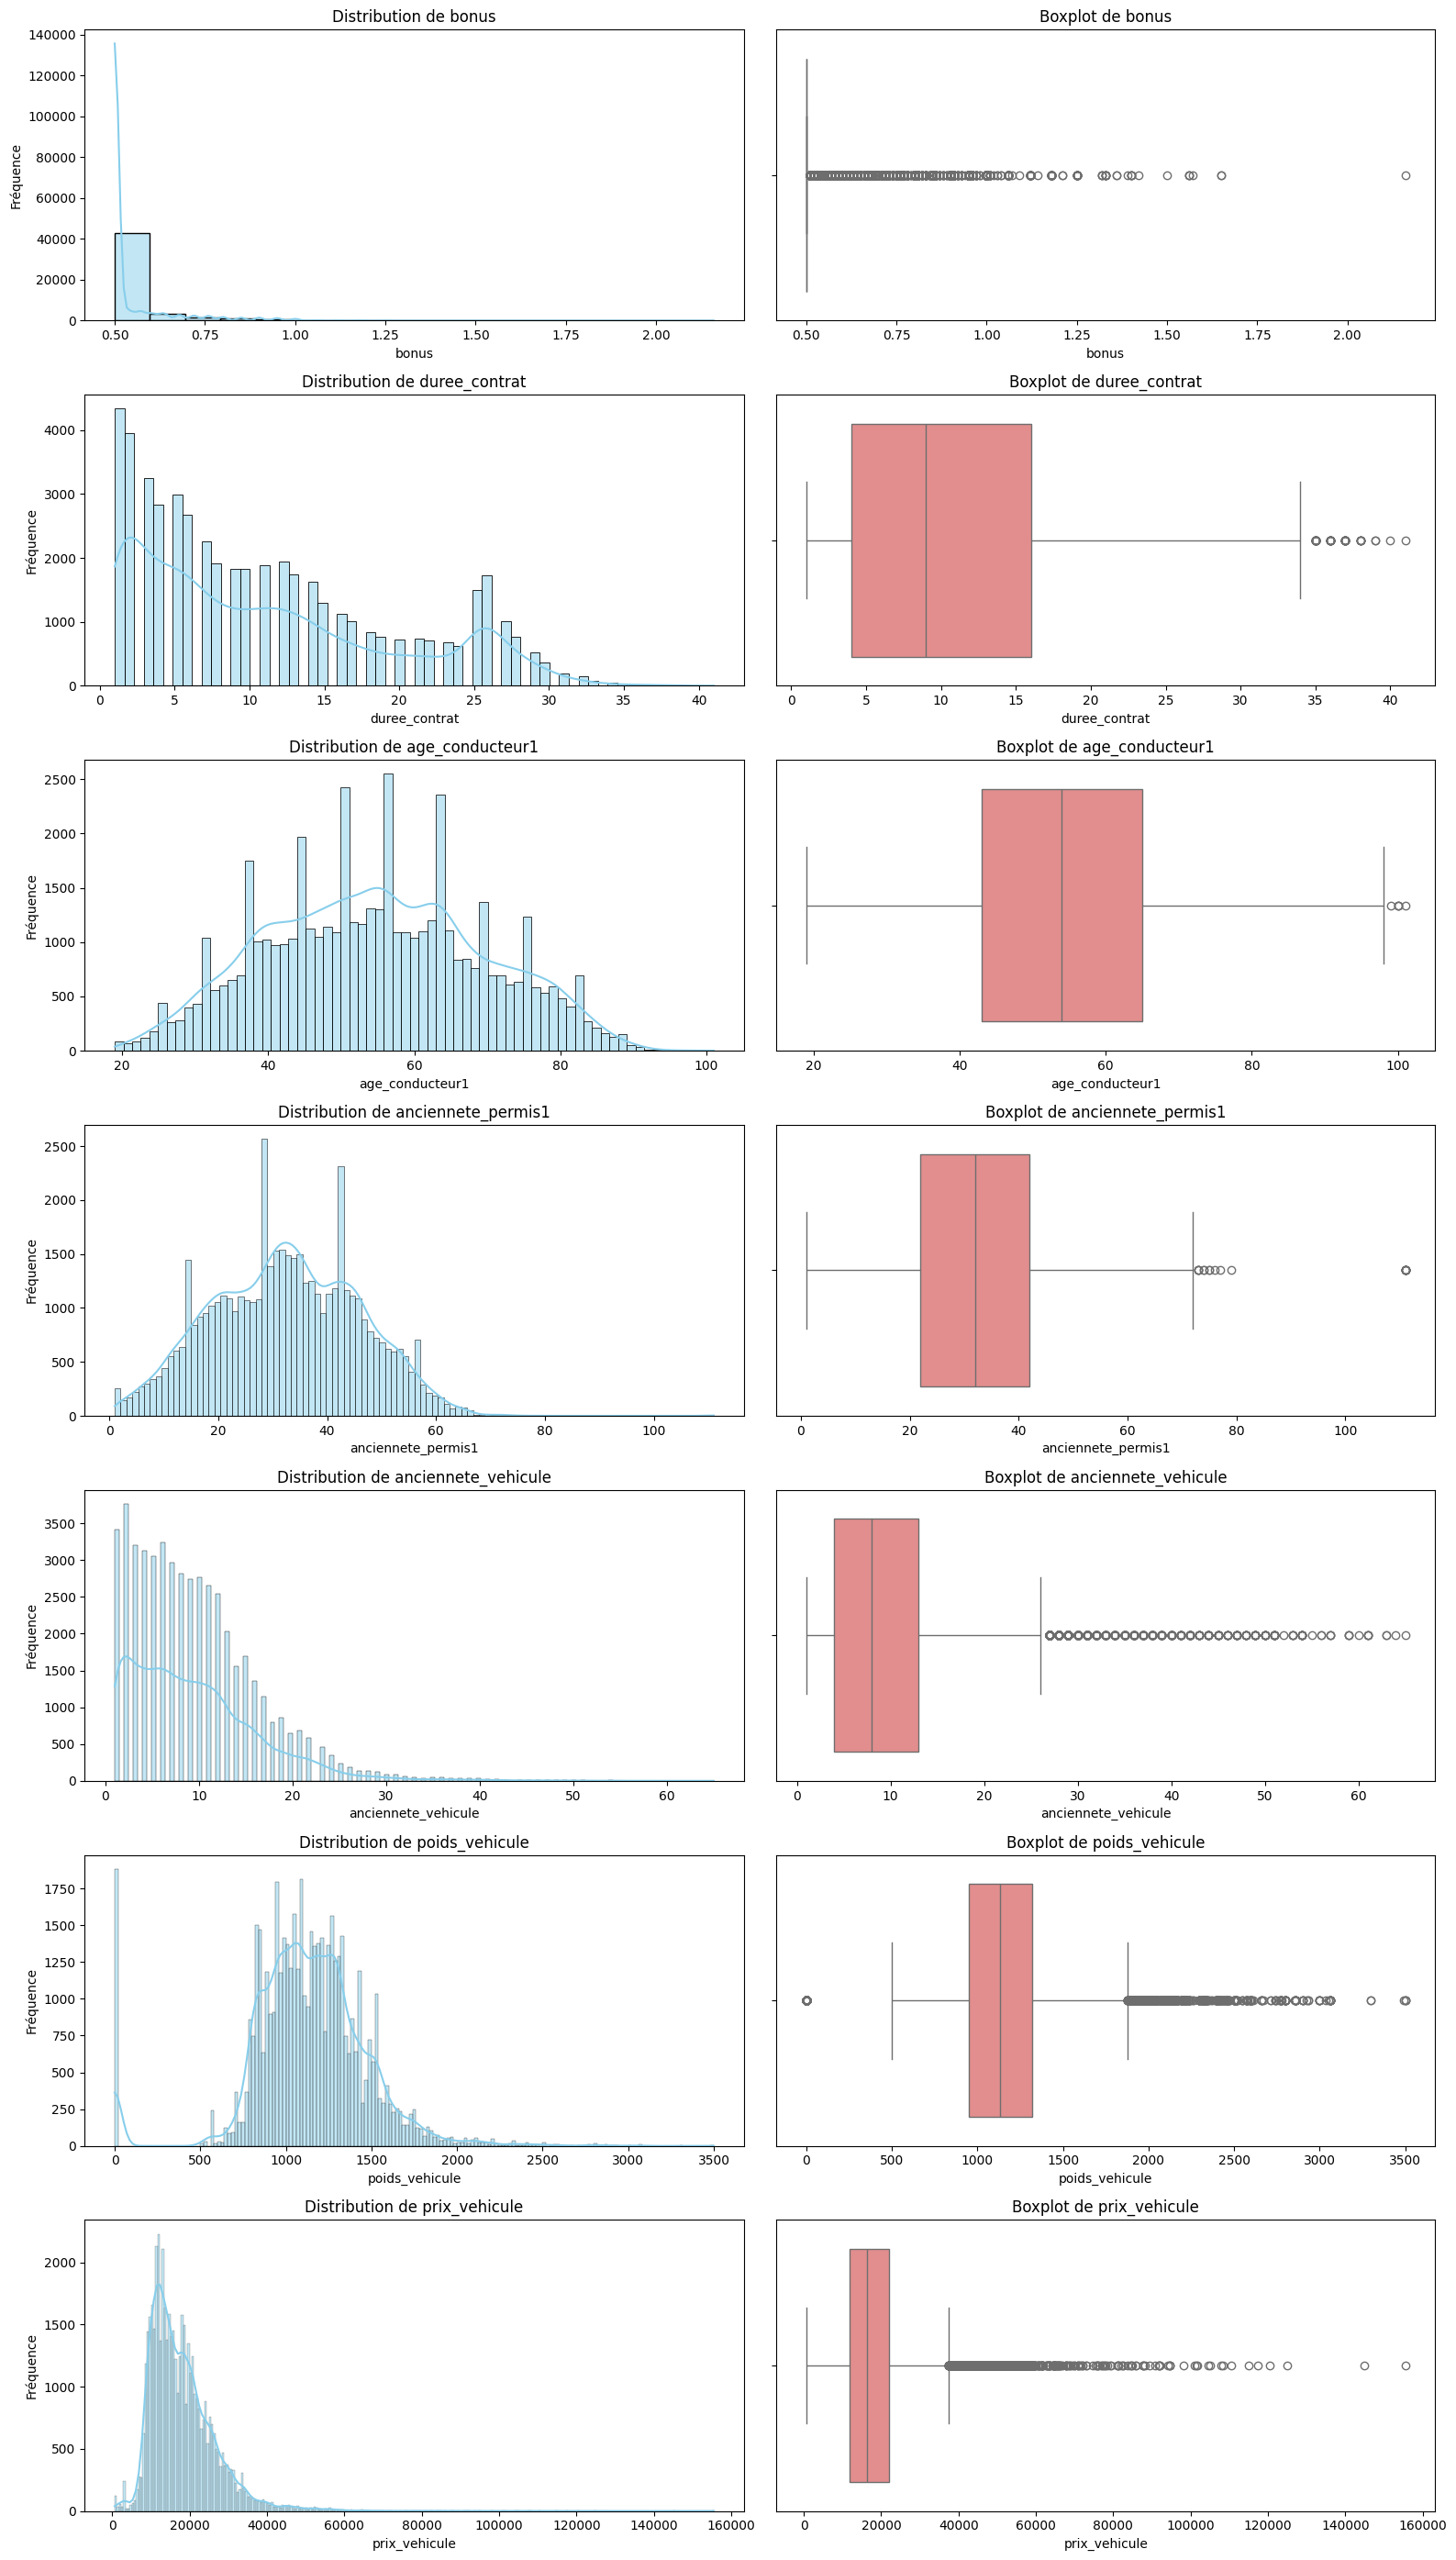

In [9]:
# 3. Analyse détaillée des variables numériques (Statistiques et détection d'aberrations)
print("=== STATISTIQUES DES VARIABLES NUMERIQUES ===")
num_cols = expl_df.select_dtypes(include=[np.number]).columns
display(expl_df[num_cols].describe())

# Sélection des principales variables numériques d'intérêt pour éviter de surcharger
visual_cols = ['bonus', 'duree_contrat', 'age_conducteur1', 'anciennete_permis1', 'anciennete_vehicule', 'poids_vehicule', 'prix_vehicule']

print("\n=== VISUALISATION DES VARIABLES NUMERIQUES ===")
fig, axes = plt.subplots(len(visual_cols), 2, figsize=(16, 4 * len(visual_cols)))

for i, col in enumerate(visual_cols):
    # Histogramme / Densité
    sns.histplot(data=expl_df, x=col, kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f"Distribution de {col}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Fréquence")

    # Boxplot pour détecter les outliers
    sns.boxplot(data=expl_df, x=col, ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f"Boxplot de {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

A propos du "bonus", en France, le coefficient de réduction-majoration (CRM) va de 0,50 (bonus maximal) à 3,50 (malus maximal), avec 1,00 au départ.
Dans ces données, on observe un malus maximal de 2.16 et un bonus max de 0.53, ce qui est cohérent selon la définition du "bonus" en assurance.


On observe des valeurs impossibles telle que poids_vehicule = 0 et le maximum de anciennete_permis1 = 111 et l'age des conducteurs à l'obtention du permis doit être > 17 ans.

On va considérer que si poids_vehicule = 0, cylindre_vehicule = 0 et age_conducteur - anciennete_permis < 17 seront remplacés par des NaN.


In [10]:
for df in [train_df, test_df]:
    df.loc[df["poids_vehicule"] == 0, "poids_vehicule"] = np.nan
    df.loc[df["cylindre_vehicule"] == 0, "cylindre_vehicule"] = np.nan
    df.loc[df["age_conducteur1"] - df["anciennete_permis1"] < 17, "anciennete_permis1"] = np.nan

Il reste du nettoyage et de la préparation de données à faire et NaN à régler.

Il reste également de l'analyse d'importance des variables à faire.

##Modèle de gravité (régression)

###Préparation

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import GammaRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_gamma_deviance, make_scorer

Target = "montant_sinistre"
to_exclude = ['index', 'id_client', 'id_vehicule', 'id_contrat', 'nombre_sinistres', 'montant_sinistre',
              'sex_conducteur1', 'sex_conducteur2', 'code_postal', 'modele_vehicule']

def preparer(df):
    df = df.copy()
    df["conducteur2"] = df["conducteur2"].map({"Yes": 1, "No": 0, 1: 1, 0: 0}).astype(int)
    cp = df["code_postal"].astype(str).str.zfill(5)
    df["departement"] = np.where(cp.str.startswith("97"), cp.str[:3], cp.str[:2])
    return df.drop(columns=to_exclude, errors="ignore")

sinistres = train_df[train_df[Target] > 0]
X = preparer(sinistres)
y = sinistres[Target]
X_test = preparer(test_df)[X.columns]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

print(X.shape, X_test.shape)
print(cat_cols)

(2917, 24) (50000, 24)
['type_contrat', 'freq_paiement', 'paiement', 'utilisation', 'essence_vehicule', 'marque_vehicule', 'type_vehicule', 'departement']


###Evaluation

In [12]:
def evaluer(nom, y_reel, y_pred):
    mae = mean_absolute_error(y_reel, y_pred)
    rmse = np.sqrt(mean_squared_error(y_reel, y_pred))
    try:
        gamma_dev = mean_gamma_deviance(y_reel, y_pred)
    except ValueError:
        gamma_dev = np.nan
    ratio = np.sum(y_pred) / np.sum(y_reel)
    print(f"[{nom}] MAE: {mae:.2f} | RMSE: {rmse:.2f} | Dev. Gamma: {gamma_dev:.4f} | Somme pred/obs: {ratio:.3f}")

###Modèle

In [13]:
preprocess_glm = ColumnTransformer([
    ("cat", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist", sparse_output=False), cat_cols),
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
])

glm = Pipeline([
    ("prep", preprocess_glm),
    ("gamma", GammaRegressor(max_iter=1000)),
])

scorer = make_scorer(mean_gamma_deviance, greater_is_better=False)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

resultats = {}
for alpha in [1e-2, 1e-1, 1, 3, 10, 30, 100]:
    glm.set_params(gamma__alpha=alpha)
    scores = -cross_val_score(glm, X_train, y_train, cv=kf, scoring=scorer)
    resultats[alpha] = scores.mean()
    print(f"alpha={alpha}: {scores.mean():.4f} ± {scores.std():.4f}")

best_alpha = min(resultats, key=resultats.get)
print("Meilleur alpha :", best_alpha)

alpha=0.01: 0.4224 ± 0.0454
alpha=0.1: 0.4053 ± 0.0375
alpha=1: 0.4014 ± 0.0343
alpha=3: 0.4020 ± 0.0330
alpha=10: 0.4043 ± 0.0317
alpha=30: 0.4063 ± 0.0309
alpha=100: 0.4073 ± 0.0306
Meilleur alpha : 1


###Evaluation finale

In [14]:
glm.set_params(gamma__alpha=best_alpha)
glm.fit(X_train, y_train)

evaluer("Baseline moy.", y_val, np.full(len(y_val), y_train.mean()))
evaluer("GLM train", y_train, glm.predict(X_train))
evaluer("GLM val", y_val, glm.predict(X_val))

[Baseline moy.] MAE: 951.91 | RMSE: 1490.53 | Dev. Gamma: 0.4102 | Somme pred/obs: 1.001
[GLM train] MAE: 933.26 | RMSE: 1442.79 | Dev. Gamma: 0.3942 | Somme pred/obs: 0.996
[GLM val] MAE: 936.36 | RMSE: 1482.80 | Dev. Gamma: 0.4025 | Somme pred/obs: 0.996


####Lecture des résultats du GLM Gamma

**Pourquoi une loi Gamma ?** Les montants de sinistres sont strictement positifs et très asymétriques : beaucoup de petits sinistres, quelques très gros (max ≈ 21 800 € pour une moyenne de 1 772 €). La loi Gamma est faite pour ce type de variable. Elle suppose que la variance croît avec le carré de la moyenne, donc une erreur de 500 € sur un sinistre de 1 000 € compte autant qu'une erreur de 5 000 € sur un sinistre de 10 000 €. Avec le lien log, le modèle est multiplicatif : $\hat{y} = \exp(\beta_0 + \beta_1 x_1 + \dots)$, donc chaque variable multiplie le montant attendu par un facteur.

**La déviance Gamma** : $D = \frac{2}{n}\sum_i \left(\frac{y_i - \hat{y}_i}{\hat{y}_i} - \ln\frac{y_i}{\hat{y}_i}\right)$. Elle vaut 0 si la prédiction est parfaite et mesure une erreur **relative**, ce qui évite que quelques gros sinistres dominent l'évaluation. Plus elle est basse, mieux c'est.

**Choix de alpha** : alpha est la pénalité L2 (ridge) sur les coefficients. La grille initiale s'arrêtait à 1, qui était aussi le meilleur, donc on ne savait pas si un alpha plus grand faisait mieux. Avec la grille étendue, la déviance remonte après alpha = 1 : l'optimum est bien à 1, ce qui correspond à une régularisation assez forte.

**Interprétation** :
- Sur la validation, la déviance passe de 0.4102 (prédire toujours la moyenne) à 0.4025 avec le GLM, soit un gain d'environ 2 %. Le RMSE et le MAE baissent aussi, mais faiblement.
- L'écart train/val est petit (0.394 contre 0.403) : le modèle ne sur-apprend pas.
- Le ratio somme prédite / somme observée est de 0.996 : le modèle est bien calibré en moyenne. C'est essentiel en tarification, sinon la prime totale encaissée ne couvre pas les sinistres.
- Conclusion : **le montant d'un sinistre est très peu expliqué par les variables disponibles**. C'est classique en assurance automobile : la fréquence est plus prévisible que la gravité, qui dépend beaucoup du hasard (circonstances de l'accident, tiers impliqué...). Il ne faut pas s'attendre à des gains spectaculaires avec d'autres modèles.

###Comparaison avec d'autres modèles

**Méthode de comparaison.** Avec seulement 2 917 sinistres, un unique découpage 80/20 laisse 584 observations en validation, et le résultat dépend beaucoup du découpage (l'écart-type de la déviance entre folds est d'environ 0.03, du même ordre que les écarts entre modèles). On utilise donc des **prédictions out-of-fold** (`cross_val_predict`) : chaque sinistre est prédit par un modèle qui ne l'a pas vu, avec les **mêmes 5 folds** (`kf`) pour tous les modèles. Les métriques sont ainsi calculées sur les 2 917 sinistres et la comparaison est équitable.

**Métriques** (fonction `evaluer`) :
- **RMSE** : métrique demandée. Elle pénalise fortement les grosses erreurs, donc elle est dominée par les quelques très gros sinistres.
- **MAE** : plus robuste, mais elle est minimisée par la *médiane* et non par la moyenne. Sur des montants asymétriques, un modèle qui optimise la MAE sous-estime le montant moyen, donc la prime.
- **Déviance Gamma** : erreur relative, adaptée aux montants.
- **Somme pred/obs** : contrôle de calibration, qui doit rester proche de 1.

On retient un modèle qui améliore la déviance et le RMSE par rapport à la baseline tout en restant calibré.

**Modèles comparés** :
- baseline (moyenne) ;
- GLM Gamma (alpha retenu) ;
- Random Forest ;
- deux Gradient Boosting (`HistGradientBoostingRegressor`), l'un avec la perte quadratique classique (`squared_error`), l'autre avec la perte Gamma (`gamma`).

Pour les arbres, pas besoin de one-hot ni de standardisation : les catégories sont encodées en entiers (`OrdinalEncoder`) et le boosting les traite nativement comme catégorielles (`categorical_features`). Les modèles d'arbres sont fortement régularisés (`min_samples_leaf=50`, peu de feuilles, early stopping), car le signal est faible et le risque de sur-apprentissage élevé.

In [15]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_predict

preprocess_arbres = ColumnTransformer([
    ("cat", OrdinalEncoder(min_frequency=20, handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ("num", SimpleImputer(strategy="median"), num_cols),
])
masque_cat = [True] * len(cat_cols) + [False] * len(num_cols)

def hgb(loss):
    return Pipeline([
        ("prep", preprocess_arbres),
        ("modele", HistGradientBoostingRegressor(
            loss=loss, learning_rate=0.03, max_iter=500, max_leaf_nodes=8, min_samples_leaf=50,
            l2_regularization=1.0, categorical_features=masque_cat,
            early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=42)),
    ])

modeles = {
    "Baseline moyenne": DummyRegressor(strategy="mean"),
    "GLM Gamma": glm,
    "RF": Pipeline([
        ("prep", preprocess_arbres),
        ("modele", RandomForestRegressor(n_estimators=500, min_samples_leaf=50, max_features=0.5, n_jobs=-1, random_state=42)),
    ]),
    "HGB squared_error": hgb("squared_error"),
    "HGB gamma": hgb("gamma"),
}

oof = {}
for nom, modele in modeles.items():
    oof[nom] = cross_val_predict(modele, X, y, cv=kf)
    evaluer(nom, y, oof[nom])

[Baseline moyenne] MAE: 953.73 | RMSE: 1464.06 | Dev. Gamma: 0.4084 | Somme pred/obs: 1.000
[GLM Gamma] MAE: 937.58 | RMSE: 1455.96 | Dev. Gamma: 0.4005 | Somme pred/obs: 0.996
[RF] MAE: 930.23 | RMSE: 1455.72 | Dev. Gamma: 0.3996 | Somme pred/obs: 1.002
[HGB squared_error] MAE: 943.15 | RMSE: 1464.72 | Dev. Gamma: 0.4071 | Somme pred/obs: 0.998
[HGB gamma] MAE: 923.75 | RMSE: 1462.44 | Dev. Gamma: 0.4061 | Somme pred/obs: 0.974


**Résultats (out-of-fold, 2 917 sinistres)** :

| Modèle | MAE | RMSE | Dév. Gamma | Somme pred/obs |
|---|---|---|---|---|
| Baseline moyenne | 953.7 | 1464.1 | 0.4084 | 1.000 |
| GLM Gamma | 937.6 | 1456.0 | 0.4005 | 0.996 |
| **RF** | 930.2 | **1455.7** | **0.3996** | 1.002 |
| HGB squared_error | 943.5 | 1464.8 | 0.4071 | 0.998 |
| HGB gamma | **923.8** | 1462.5 | 0.4062 | 0.974 |

- **RF et GLM sont au coude à coude** et sont les seuls à battre nettement la baseline en déviance et en RMSE.
- **Le boosting ne fait pas mieux**. Le HGB `squared_error` est même au niveau de la baseline en RMSE. Des réglages plus régularisés (taux d'apprentissage 0.01-0.02, `min_samples_leaf` 100-200, 4 feuilles) ont été testés à part sans changer la conclusion (déviance ≥ 0.404). Le boosting corrige les résidus itérativement, ce qui le rend très bon quand il y a du signal. Ici, il finit surtout par modéliser du bruit.
- Le HGB `gamma` a la meilleure MAE, mais il **sous-estime la somme des sinistres de 2.6 %**. C'est l'illustration du piège de la MAE : un modèle qui tire vers la médiane a une MAE plus basse, mais il sous-tarifie.
- On retient le **Random Forest** : il est meilleur sur la déviance et le RMSE, il est bien calibré, et la moyenne de nombreux arbres profonds mais contraints est naturellement robuste au bruit. Le GLM reste une alternative quasi équivalente et plus interprétable.

In [16]:
def deciles(pred, y_reel):
    t = pd.DataFrame({"pred": pred, "reel": y_reel.values})
    t["decile"] = pd.qcut(t["pred"].rank(method="first"), 10, labels=range(1, 11))
    return t.groupby("decile", observed=True).agg(
        pred_moy=("pred", "mean"), reel_moy=("reel", "mean"), effectif=("reel", "size")).round(0)

for nom in ["GLM Gamma", "RF", "HGB squared_error", "HGB gamma"]:
    print(nom)
    print(deciles(oof[nom], y))

GLM Gamma
        pred_moy  reel_moy  effectif
decile                              
1         1491.0    1378.0       292
2         1624.0    1650.0       292
3         1686.0    1644.0       291
4         1731.0    1807.0       292
5         1770.0    1798.0       292
6         1801.0    1766.0       291
7         1831.0    1973.0       292
8         1862.0    1929.0       291
9         1897.0    1920.0       292
10        1960.0    1853.0       292
RF
        pred_moy  reel_moy  effectif
decile                              
1         1357.0    1304.0       292
2         1536.0    1653.0       292
3         1652.0    1599.0       291
4         1720.0    1805.0       292
5         1777.0    1809.0       292
6         1829.0    2014.0       291
7         1874.0    1971.0       292
8         1925.0    1758.0       291
9         1988.0    1787.0       292
10        2096.0    2019.0       292
HGB squared_error
        pred_moy  reel_moy  effectif
decile                              
1      

**Tableau par déciles.** On trie les sinistres selon la prédiction, on les découpe en 10 groupes de même taille, puis on compare dans chaque groupe le montant moyen prédit au montant moyen réel. Un bon modèle a des montants réels **croissants** d'un décile à l'autre (il sait classer) et proches des prédictions (il est calibré par groupe).

- Tous les modèles séparent assez bien le premier décile (sinistres réels ≈ 1 300-1 500 €) du reste (≈ 1 800-2 000 €), mais au-delà du 5e décile la courbe des montants réels est quasiment plate : **le modèle sait repérer les petits sinistres mais pas les gros**.
- Les deux boostings prédisent environ 2 200-2 250 € dans le 10e décile pour un réel d'environ 1 850 € : ils sont **trop confiants** sur leurs prédictions extrêmes (sur-apprentissage). Le GLM et le RF ont une plage de prédictions plus resserrée et plus honnête.
- C'est cohérent avec le choix du RF (ou du GLM) pour la gravité. L'essentiel de la segmentation de la prime pure viendra du modèle de fréquence.

###Importance des variables et sélection

**Pourquoi le faire ici ?** Le modèle de gravité apprend sur seulement 2 917 sinistres avec 24 variables, dont plusieurs très corrélées (prix, puissance, cylindrée, vitesse, poids). Avec si peu de signal, chaque variable inutile laisse aux arbres une occasion supplémentaire de découper sur du bruit. Retirer ces variables peut donc **améliorer** le modèle, pas seulement le simplifier.

**Méthode : importance par permutation, calculée hors échantillon.** Pour chaque fold de `kf`, on entraîne le RF sur 4/5 des sinistres, puis on mélange une variable à la fois sur le 1/5 restant et on mesure de combien la déviance Gamma se dégrade. Une variable utile fait monter la déviance quand on la mélange (gain > 0). Une variable dont le mélange ne change rien, ou améliore la déviance (gain < 0), n'apporte pas d'information généralisable.

On n'utilise pas `feature_importances_` du Random Forest (importance MDI) : elle est calculée sur le jeu d'entraînement et favorise les variables à beaucoup de valeurs distinctes (continues, `marque_vehicule`, `departement`), même quand elles ne servent qu'à apprendre du bruit.

**Limite à garder en tête :** quand deux variables sont corrélées, mélanger l'une ne coûte presque rien car le modèle se rabat sur l'autre. Une importance faible ne veut donc pas dire « inutile » si une variable jumelle est présente. C'est pourquoi on confirme ensuite par des tests de retrait/ajout réels.

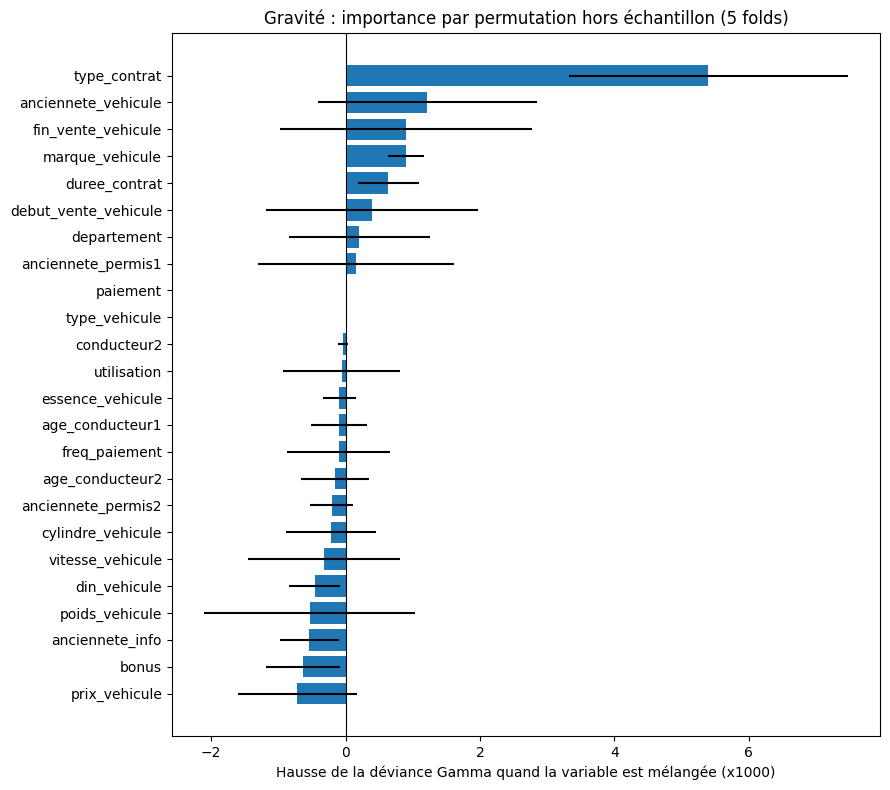

,gain_deviance_x1000,ecart_type_x1000,folds_positifs
type_contrat,5.40,2.08,5
anciennete_vehicule,1.22,1.63,4
fin_vente_vehicule,0.90,1.88,4
marque_vehicule,0.90,0.27,5
duree_contrat,0.64,0.46,5
debut_vente_vehicule,0.39,1.58,3
departement,0.21,1.05,4
anciennete_permis1,0.15,1.46,2
paiement,0.00,0.00,3
type_vehicule,0.00,0.00,3


In [17]:
from sklearn.inspection import permutation_importance

def rf_gravite(cols, min_samples_leaf=50, max_features=0.5):
    cat = [c for c in cols if c in cat_cols]
    num = [c for c in cols if c in num_cols]
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(min_frequency=20, handle_unknown="use_encoded_value", unknown_value=-1), cat),
        ("num", SimpleImputer(strategy="median"), num),
    ])
    return Pipeline([
        ("prep", prep),
        ("modele", RandomForestRegressor(n_estimators=300, min_samples_leaf=min_samples_leaf,
                                         max_features=max_features, n_jobs=-1, random_state=42)),
    ])

def score_deviance(modele, X_val, y_val):
    return -mean_gamma_deviance(y_val, modele.predict(X_val))

toutes = list(X.columns)
importances = []
for idx_tr, idx_va in kf.split(X):
    m = rf_gravite(toutes).fit(X.iloc[idx_tr], y.iloc[idx_tr])
    pi = permutation_importance(m, X.iloc[idx_va], y.iloc[idx_va], scoring=score_deviance,
                                n_repeats=10, random_state=0, n_jobs=-1)
    importances.append(pi.importances_mean)

imp = pd.DataFrame(importances, columns=toutes)
imp_grav = pd.DataFrame({
    "gain_deviance_x1000": imp.mean() * 1000,
    "ecart_type_x1000": imp.std() * 1000,
    "folds_positifs": (imp > 0).sum(),
}).sort_values("gain_deviance_x1000")

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(imp_grav.index, imp_grav["gain_deviance_x1000"], xerr=imp_grav["ecart_type_x1000"], color="tab:blue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Hausse de la déviance Gamma quand la variable est mélangée (x1000)")
ax.set_title("Gravité : importance par permutation hors échantillon (5 folds)")
plt.tight_layout()
plt.show()

display(imp_grav.sort_values("gain_deviance_x1000", ascending=False).round(2))

**Lecture.**
- `type_contrat` écrase tout le reste, et son importance est positive sur les 5 folds. C'est cohérent avec l'analyse bivariée : le montant moyen d'un sinistre est d'environ 1 850 € en contrat Maxi contre 1 370-1 510 € en Mini/Median. Logique métier : un contrat Maxi couvre plus de garanties (dommages tous accidents, vol...), donc indemnise davantage par sinistre.
- Viennent ensuite l'âge du véhicule (`anciennete_vehicule`, `fin_vente_vehicule`, `debut_vente_vehicule`, trois mesures du même phénomène), `marque_vehicule` (positive sur les 5 folds) et `duree_contrat`.
- Une majorité de variables ont une importance **négative** : `prix_vehicule`, `bonus`, `anciennete_info`, `poids_vehicule`, `din_vehicule`... Les mélanger améliore légèrement la prédiction, ce qui signifie que le modèle s'en sert pour sur-apprendre.

On teste maintenant plusieurs sous-ensembles avec une **validation croisée répétée** (5 folds × 3 découpages différents), car les écarts attendus (quelques millièmes de déviance) sont du même ordre que le bruit d'un seul découpage. Tous les sous-ensembles sont évalués sur les mêmes découpages, donc les écarts entre eux sont comparables.

In [18]:
def evaluer_cv(cols, n_rep=3, **params):
    devs, rmses, ratios = [], [], []
    for r in range(n_rep):
        cv = KFold(n_splits=5, shuffle=True, random_state=r)
        p = cross_val_predict(rf_gravite(cols, **params), X[cols], y, cv=cv)
        devs.append(mean_gamma_deviance(y, p))
        rmses.append(np.sqrt(mean_squared_error(y, p)))
        ratios.append(p.sum() / y.sum())
    return {"deviance": np.mean(devs), "ecart_type_dev": np.std(devs), "RMSE": np.mean(rmses), "somme_pred_obs": np.mean(ratios)}

dev_baseline = np.mean([mean_gamma_deviance(y, cross_val_predict(DummyRegressor(), X, y, cv=KFold(5, shuffle=True, random_state=r))) for r in range(3)])
print(f"Baseline moyenne : déviance {dev_baseline:.4f}")

importance_positive = imp_grav.index[imp_grav["gain_deviance_x1000"] > 0].tolist()
top5 = imp_grav.sort_values("gain_deviance_x1000", ascending=False).index[:5].tolist()

sous_ensembles = {
    "Toutes (24)": toutes,
    f"Importance > 0 ({len(importance_positive)})": importance_positive,
    "Top 5": top5,
    "type_contrat seul": ["type_contrat"],
}
comparaison_vars = pd.DataFrame({nom: evaluer_cv(cols) for nom, cols in sous_ensembles.items()}).T
display(comparaison_vars.round(4))
print("Top 5 :", top5)

Baseline moyenne : déviance 0.4087


,deviance,ecart_type_dev,RMSE,somme_pred_obs
Toutes (24),0.4012,0.0022,1457.4029,1.0009
Importance > 0 (10),0.4002,0.0011,1456.2977,1.0000
Top 5,0.3984,0.0009,1454.0973,1.0007
type_contrat seul,0.4010,0.0005,1456.6442,1.0001


Top 5 : ['type_contrat', 'anciennete_vehicule', 'fin_vente_vehicule', 'marque_vehicule', 'duree_contrat']


Garder seulement les 5 variables les plus importantes fait mieux que garder les 24. On affine ensuite autour du top 5 en testant, une par une, le **retrait** de chaque variable retenue et l'**ajout** de chaque variable écartée. C'est ce test qui tranche pour les variables corrélées, là où la permutation est trompeuse. (Cellule un peu longue : environ 25 configurations × 15 entraînements.)

In [19]:
ref = evaluer_cv(top5)["deviance"]
tests = []
for c in top5:
    tests.append({"test": f"- {c}", "deviance": evaluer_cv([v for v in top5 if v != c])["deviance"]})
for c in [v for v in toutes if v not in top5]:
    tests.append({"test": f"+ {c}", "deviance": evaluer_cv(top5 + [c])["deviance"]})

tests = pd.DataFrame(tests)
tests["ecart_x1000"] = (tests["deviance"] - ref) * 1000
display(tests.sort_values("ecart_x1000").round(4))

,test,deviance,ecart_x1000
19,+ vitesse_vehicule,0.3970,-1.3515
2,- fin_vente_vehicule,0.3975,-0.8727
4,- duree_contrat,0.3982,-0.2115
11,+ age_conducteur1,0.3982,-0.1898
7,+ freq_paiement,0.3987,0.3188
15,+ cylindre_vehicule,0.3989,0.5152
17,+ essence_vehicule,0.3989,0.5222
8,+ paiement,0.3990,0.5522
10,+ conducteur2,0.3990,0.5819
20,+ type_vehicule,0.3990,0.6094


**Lecture** (écart négatif = le modèle s'améliore) :
- Retirer `type_contrat`, `anciennete_vehicule` ou `marque_vehicule` dégrade nettement la déviance : ces trois variables portent le signal.
- Retirer `fin_vente_vehicule` **améliore** le modèle : elle est redondante avec `anciennete_vehicule` (même information, l'âge du modèle de voiture). `duree_contrat` n'apporte rien non plus.
- Parmi les ajouts, seule `vitesse_vehicule` améliore clairement. C'est le meilleur représentant du groupe « puissance » : elle résume à elle seule prix, DIN, cylindrée et poids, qui eux dégradent le modèle. Une voiture rapide coûte plus cher à réparer, l'intuition métier est respectée.
- `departement` dégrade : avec plus de 90 modalités pour 2 917 sinistres, chaque département a trop peu de sinistres pour estimer un effet fiable.

On compare donc les sous-ensembles finaux, puis on vérifie que les hyperparamètres du RF restent adaptés avec moins de variables.

In [32]:
cols_gravite = ["type_contrat", "anciennete_vehicule", "marque_vehicule", "vitesse_vehicule"]

finaux = {
    "Toutes (24)": toutes,
    "Top 5": top5,
    "contrat + âge véhicule + marque": cols_gravite[:3],
    "contrat + âge véhicule": cols_gravite[:2],
    "+ vitesse_vehicule (retenu)": cols_gravite,
}
display(pd.DataFrame({nom: evaluer_cv(cols) for nom, cols in finaux.items()}).T.round(4))

grille = []
for leaf in [30, 50, 100]:
    for mf in [0.5, 1.0]:
        r = evaluer_cv(cols_gravite, min_samples_leaf=leaf, max_features=mf)
        grille.append({"min_samples_leaf": leaf, "max_features": mf, **r})
display(pd.DataFrame(grille).sort_values("deviance").round(4))

,deviance,ecart_type_dev,RMSE,somme_pred_obs
Toutes (24),0.4012,0.0022,1457.4029,1.0009
Top 5,0.3984,0.0009,1454.0973,1.0007
contrat + âge véhicule + marque,0.3963,0.0010,1451.5731,1.0001
contrat + âge véhicule,0.3970,0.0004,1452.6989,1.0003
+ vitesse_vehicule (retenu),0.3949,0.0012,1449.9622,1.0005


,min_samples_leaf,max_features,deviance,ecart_type_dev,RMSE,somme_pred_obs
2,50,0.5,0.3949,0.0012,1449.9622,1.0005
0,30,0.5,0.3954,0.0014,1451.1252,1.0003
4,100,0.5,0.3956,0.0008,1450.8539,1.0004
3,50,1.0,0.3957,0.0019,1451.0836,1.0008
5,100,1.0,0.3964,0.0011,1451.5532,1.0006
1,30,1.0,0.3975,0.0022,1453.6995,1.0007


**Résultat.** Avec 4 variables au lieu de 24, le RF passe d'une déviance d'environ 0.401 à 0.395, et le RMSE baisse aussi. Le gain par rapport à la baseline (0.409) est donc pratiquement doublé, avec une calibration toujours proche de 1. Les hyperparamètres actuels (`min_samples_leaf=50`, `max_features=0.5`) restent parmi les meilleurs, on les garde.

**Prudence sur le gain mesuré.** Les variables ont été choisies avec la même validation croisée que celle qui mesure le gain : le chiffre est donc légèrement optimiste (biais de sélection). La conclusion qualitative est en revanche solide : moins de variables, et des variables qui ont un sens métier, donnent un modèle plus stable. Le vrai juge sera le score Kaggle.

**Réglementation.** Aucune des 4 variables retenues ne pose de problème : le sexe a été exclu dès la préparation, et le département (qui peut servir de proxy de caractéristiques protégées) n'est finalement pas retenu.

In [27]:
pred_oof_final = cross_val_predict(rf_gravite(cols_gravite), X[cols_gravite], y, cv=kf)
evaluer("RF 24 variables", y, oof["RF"])
evaluer("RF 4 variables", y, pred_oof_final)
display(deciles(pred_oof_final, y))

[RF 24 variables] MAE: 930.23 | RMSE: 1455.72 | Dev. Gamma: 0.3996 | Somme pred/obs: 1.002
[RF 4 variables] MAE: 927.23 | RMSE: 1453.07 | Dev. Gamma: 0.3972 | Somme pred/obs: 1.001


,pred_moy,reel_moy,effectif
decile,,,
1,1348.0,1388.0,292
2,1499.0,1482.0,292
3,1687.0,1784.0,291
4,1766.0,1893.0,292
5,1802.0,1853.0,292
6,1837.0,1764.0,291
7,1863.0,1733.0,292
8,1891.0,1718.0,291
9,1968.0,2199.0,292


**Vérification finale.** Sur les mêmes folds que la comparaison précédente, le RF à 4 variables bat le RF à 24 variables sur toutes les métriques (déviance 0.3946 contre 0.3996, RMSE 1449 contre 1456) et reste calibré (somme pred/obs 1.001).

Le gain le plus visible est dans le tableau par déciles : avec 24 variables, la courbe des montants réels était plate à partir du 5e décile et le modèle surestimait le dernier décile. Avec 4 variables, les montants réels croissent presque régulièrement du 1er (≈ 1 400 €) au 10e décile (≈ 2 180 €), et le 10e décile est bien calibré (2 138 € prédits pour 2 180 € observés). **Le modèle sait maintenant repérer les sinistres coûteux**, ce qui était la question posée par l'énoncé.

####Prediction sur le test

In [30]:
nom_retenu = "RF 4 variables"
modele_final = rf_gravite(cols_gravite)

modele_final.fit(X[cols_gravite], y)
pred_gravite_test = modele_final.predict(X_test[cols_gravite])

gravite_test = pd.DataFrame({"index": test_df["index"], "gravite": pred_gravite_test})

print(nom_retenu)
print(gravite_test["gravite"].describe())
print("Moyenne observée des sinistres :", y.mean())

gravite_test.to_csv("predictions_gravite_test.csv", index=False)

RF 2 variables
count    50000.000000
mean      1667.930125
std        244.553868
min       1292.399059
25%       1414.092683
50%       1736.746491
75%       1842.839549
max       2058.722890
Name: gravite, dtype: float64
Moyenne observée des sinistres : 1771.8434007541994


Unification des prédiction de classification et des prédiction de régression.

In [31]:
gravite = pd.read_csv("predictions_gravite_test.csv")
proba = pd.read_csv("predictions_proba_test.csv")

df = proba.merge(gravite, on="index", how="inner")
df["pred"] = df["proba"] * df["gravite"]

print(len(proba), len(gravite), len(df))

df[["index", "pred"]].to_csv("prediction_prime_test.csv", index=False)

50000 50000 50000
